# Plot Fortran

/var/folders/4b/21l8l7f16454_gmz0828vrsr0000gn/T/ipykernel_40748/2373715220.py:82: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_yscale('log')


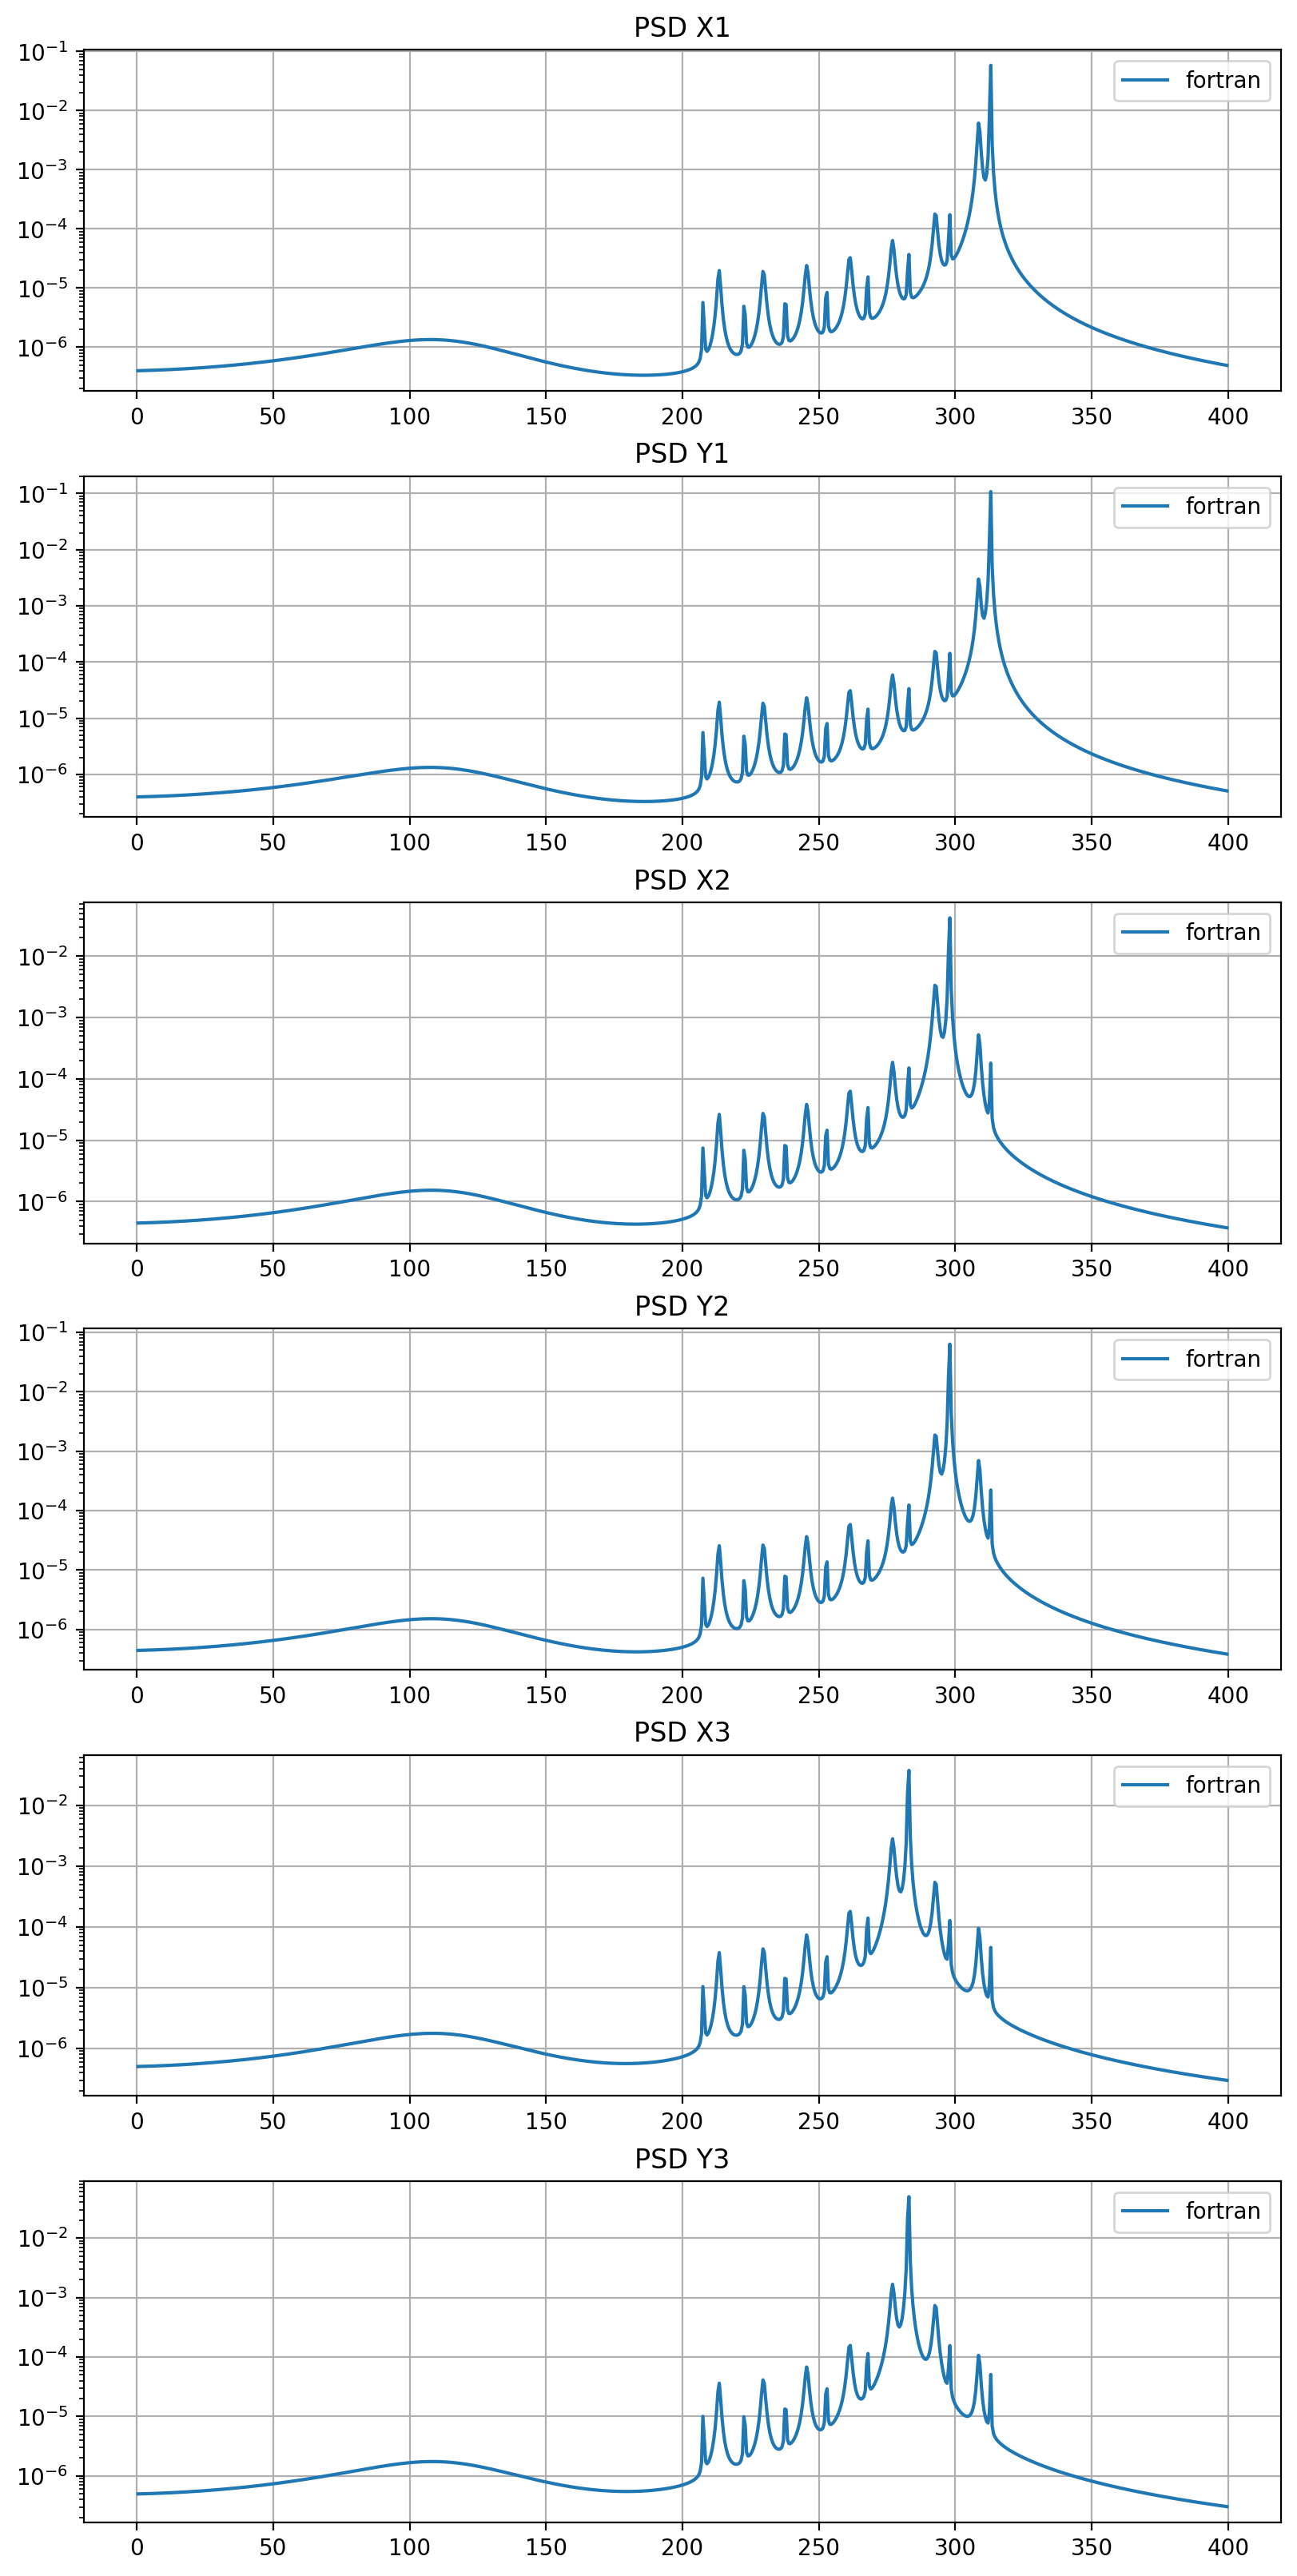

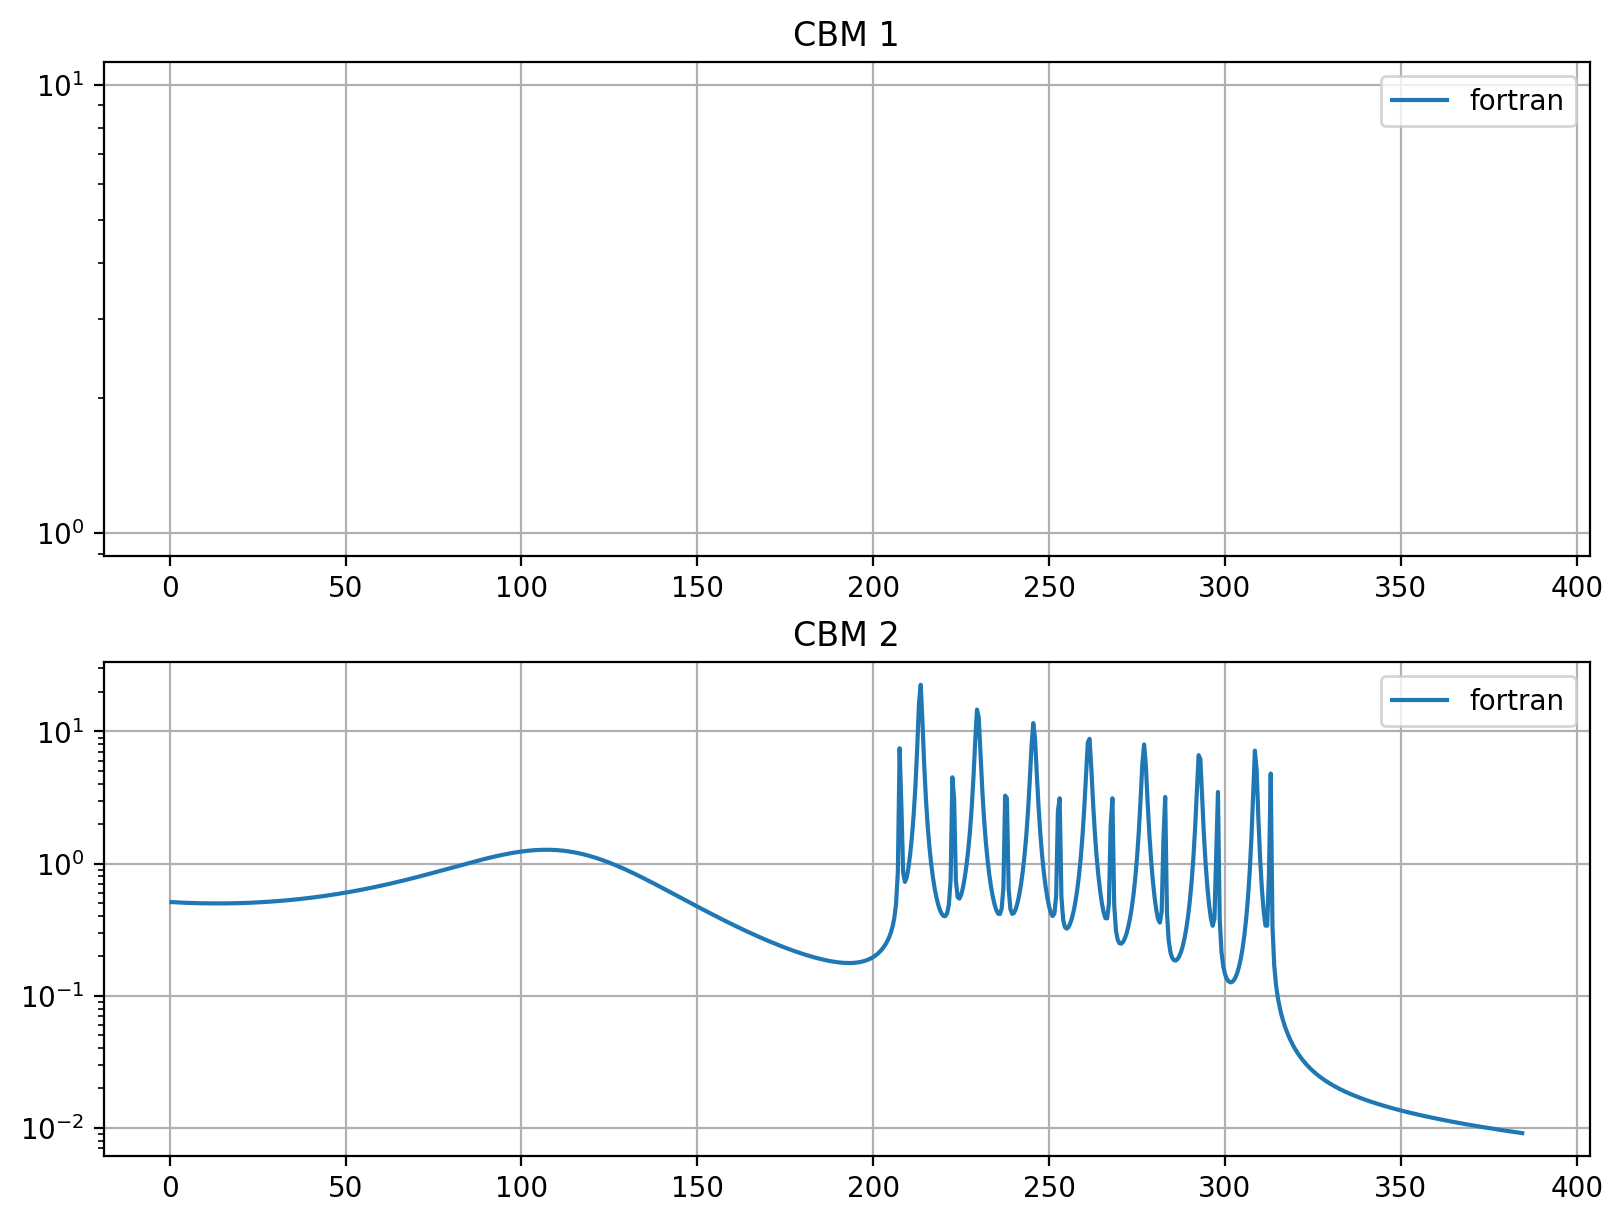

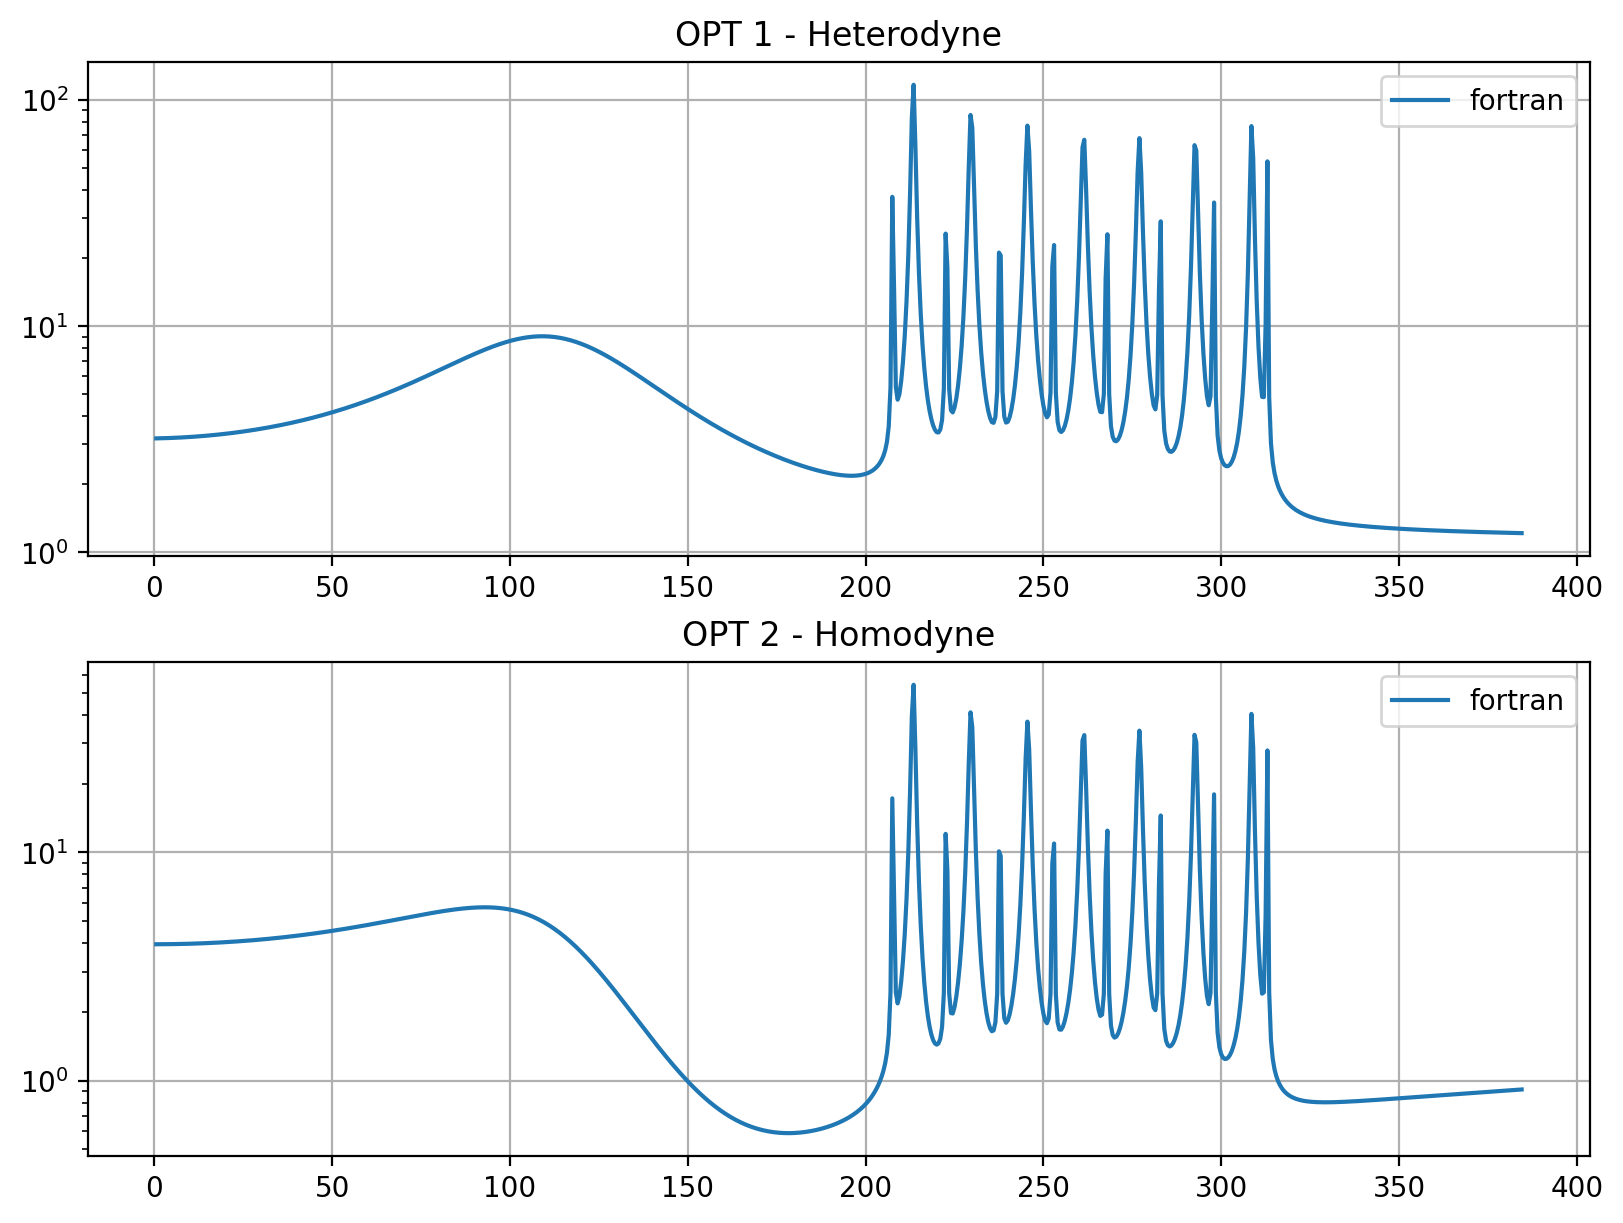

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# NOTE: to get the data from this fortran scripts, run
# gfortran -O2 -llapack NParticle.f90  3DEQRom.f90 ParametersNpair.f90 Suscept.f90 PSD.f90 NoiseVec2D.f90; ./a.out

root = '../fortran/'

plt.rcParams['figure.dpi'] = 200
plt.rcParams['figure.figsize'] = (8, 6)

PSD_fig = plt.figure(layout='constrained', figsize=(8, 16))
CBM_fig = plt.figure(layout='constrained')
OPT_fig = plt.figure(layout='constrained')

PSD_ax_dict = PSD_fig.subplot_mosaic([
        ['PSD_1'],
        ['PSD_2'],
        ['PSD_3'],
        ['PSD_4'],
        ['PSD_5'],
        ['PSD_6'],
])
PSD_ax_1 = PSD_ax_dict['PSD_1']
PSD_ax_2 = PSD_ax_dict['PSD_2']
PSD_ax_3 = PSD_ax_dict['PSD_3']
PSD_ax_4 = PSD_ax_dict['PSD_4']
PSD_ax_5 = PSD_ax_dict['PSD_5']
PSD_ax_6 = PSD_ax_dict['PSD_6']

CBM_ax_dict = CBM_fig.subplot_mosaic([
    ['CBM_1'],
    ['CBM_2'],
])
CBM_ax_1 = CBM_ax_dict['CBM_1']
CBM_ax_2 = CBM_ax_dict['CBM_2']

OPT_ax_dict = OPT_fig.subplot_mosaic([
    ['OPT_1'],
    ['OPT_2'],
])
OPT_ax_1 = OPT_ax_dict['OPT_1']
OPT_ax_2 = OPT_ax_dict['OPT_2']

XYZ_file = root + 'FTanXYZ.dat'
CBM_file = root +'FTCBM.dat'
OPT_file = root + 'FTanOPT.dat'

xyz_data = np.loadtxt(XYZ_file)
cbm_data = np.loadtxt(CBM_file)
opt_data = np.loadtxt(OPT_file)

root_name = 'fortran'
PSD_ax_1.plot(xyz_data[:, 0], xyz_data[:, 1], label=root_name)
PSD_ax_2.plot(xyz_data[:, 0], xyz_data[:, 2], label=root_name)
PSD_ax_3.plot(xyz_data[:, 0], xyz_data[:, 3], label=root_name)
PSD_ax_4.plot(xyz_data[:, 0], xyz_data[:, 4], label=root_name)
PSD_ax_5.plot(xyz_data[:, 0], xyz_data[:, 5], label=root_name)
PSD_ax_6.plot(xyz_data[:, 0], xyz_data[:, 6], label=root_name)

CBM_ax_1.plot(cbm_data[:, 0], cbm_data[:, 1], label=root_name)
CBM_ax_2.plot(cbm_data[:, 0], cbm_data[:, 2], label=root_name)

OPT_ax_1.plot(opt_data[:, 0], opt_data[:, 1], label=root_name)
OPT_ax_2.plot(opt_data[:, 0], opt_data[:, 2], label=root_name)

PSD_ax_1.set_title('PSD X1')
PSD_ax_2.set_title('PSD Y1')
PSD_ax_3.set_title('PSD X2')
PSD_ax_4.set_title('PSD Y2')
PSD_ax_5.set_title('PSD X3')
PSD_ax_6.set_title('PSD Y3')

CBM_ax_1.set_title('CBM 1')
CBM_ax_2.set_title('CBM 2')

OPT_ax_1.set_title('OPT 1 - Heterodyne')
OPT_ax_2.set_title('OPT 2 - Homodyne')

for ax_dict in [PSD_ax_dict, CBM_ax_dict, OPT_ax_dict]:
    for ax in ax_dict.values():
        ax.set_yscale('log')
        ax.legend()
        ax.grid()

plt.show()


In [3]:
# kHz step size of Fortran data
xyz_data[:, 0][1] - xyz_data[:, 0][0]

0.5

# Spectral method comparisons

MultiTrap(
    num_traps = 8
    Cartesian_axes_per_trap = 2
    ω_range = [0.0, 399.5] kHz
    num_ω_points = 800

    setup_hybridisation_power_series = False
    compare_Rjk_calculations = False

    id(gas) = 6085300048
    id(cavity) = 4673023248
)
toy_params = {
    type = pairs
    first_Ωx = 312.0 kHz
    Ω_gap = 15.0 kHz
    Ωz_to_Ωx_multiplier = 10.0

    ρ = 2200.0 kg/m³
    r = 75.0 nm
    m = 3.88772e-18 kg

    P = 0.0 mbar
    T = 300.0 K
    〈v〉 = 500.0 m/s

    all Ωx = [312. 297. 282. 267. 252. 237. 222. 207. 192.] kHz
    all Ωy = [313.5 298.5 283.5 268.5 253.5 238.5 223.5 208.5] kHz
    all Ωz = [31.2 29.7 28.2 26.7 25.2 23.7 22.2 20.7 19.2] kHz

    Γ_formula = 9.82508e-04 Hz
    Γ_formula_from_Antonio_paper = (1 + π/8) m_gas〈v〉P / (kBT) / (ρr) = 7.78395e-04 Hz
    Γ_formula_from_Tania_paper = 15Pr²/(m〈v〉) = 6.90826e-04 Hz
    Γ_formula_from_Tania_fortran = 16P/(πρr〈v〉) = 9.82508e-04 Hz

    gx = -40.00000 kHz
    gy = -40.00000 kHz
    gz = 0.00000 kHz

    gxy = 

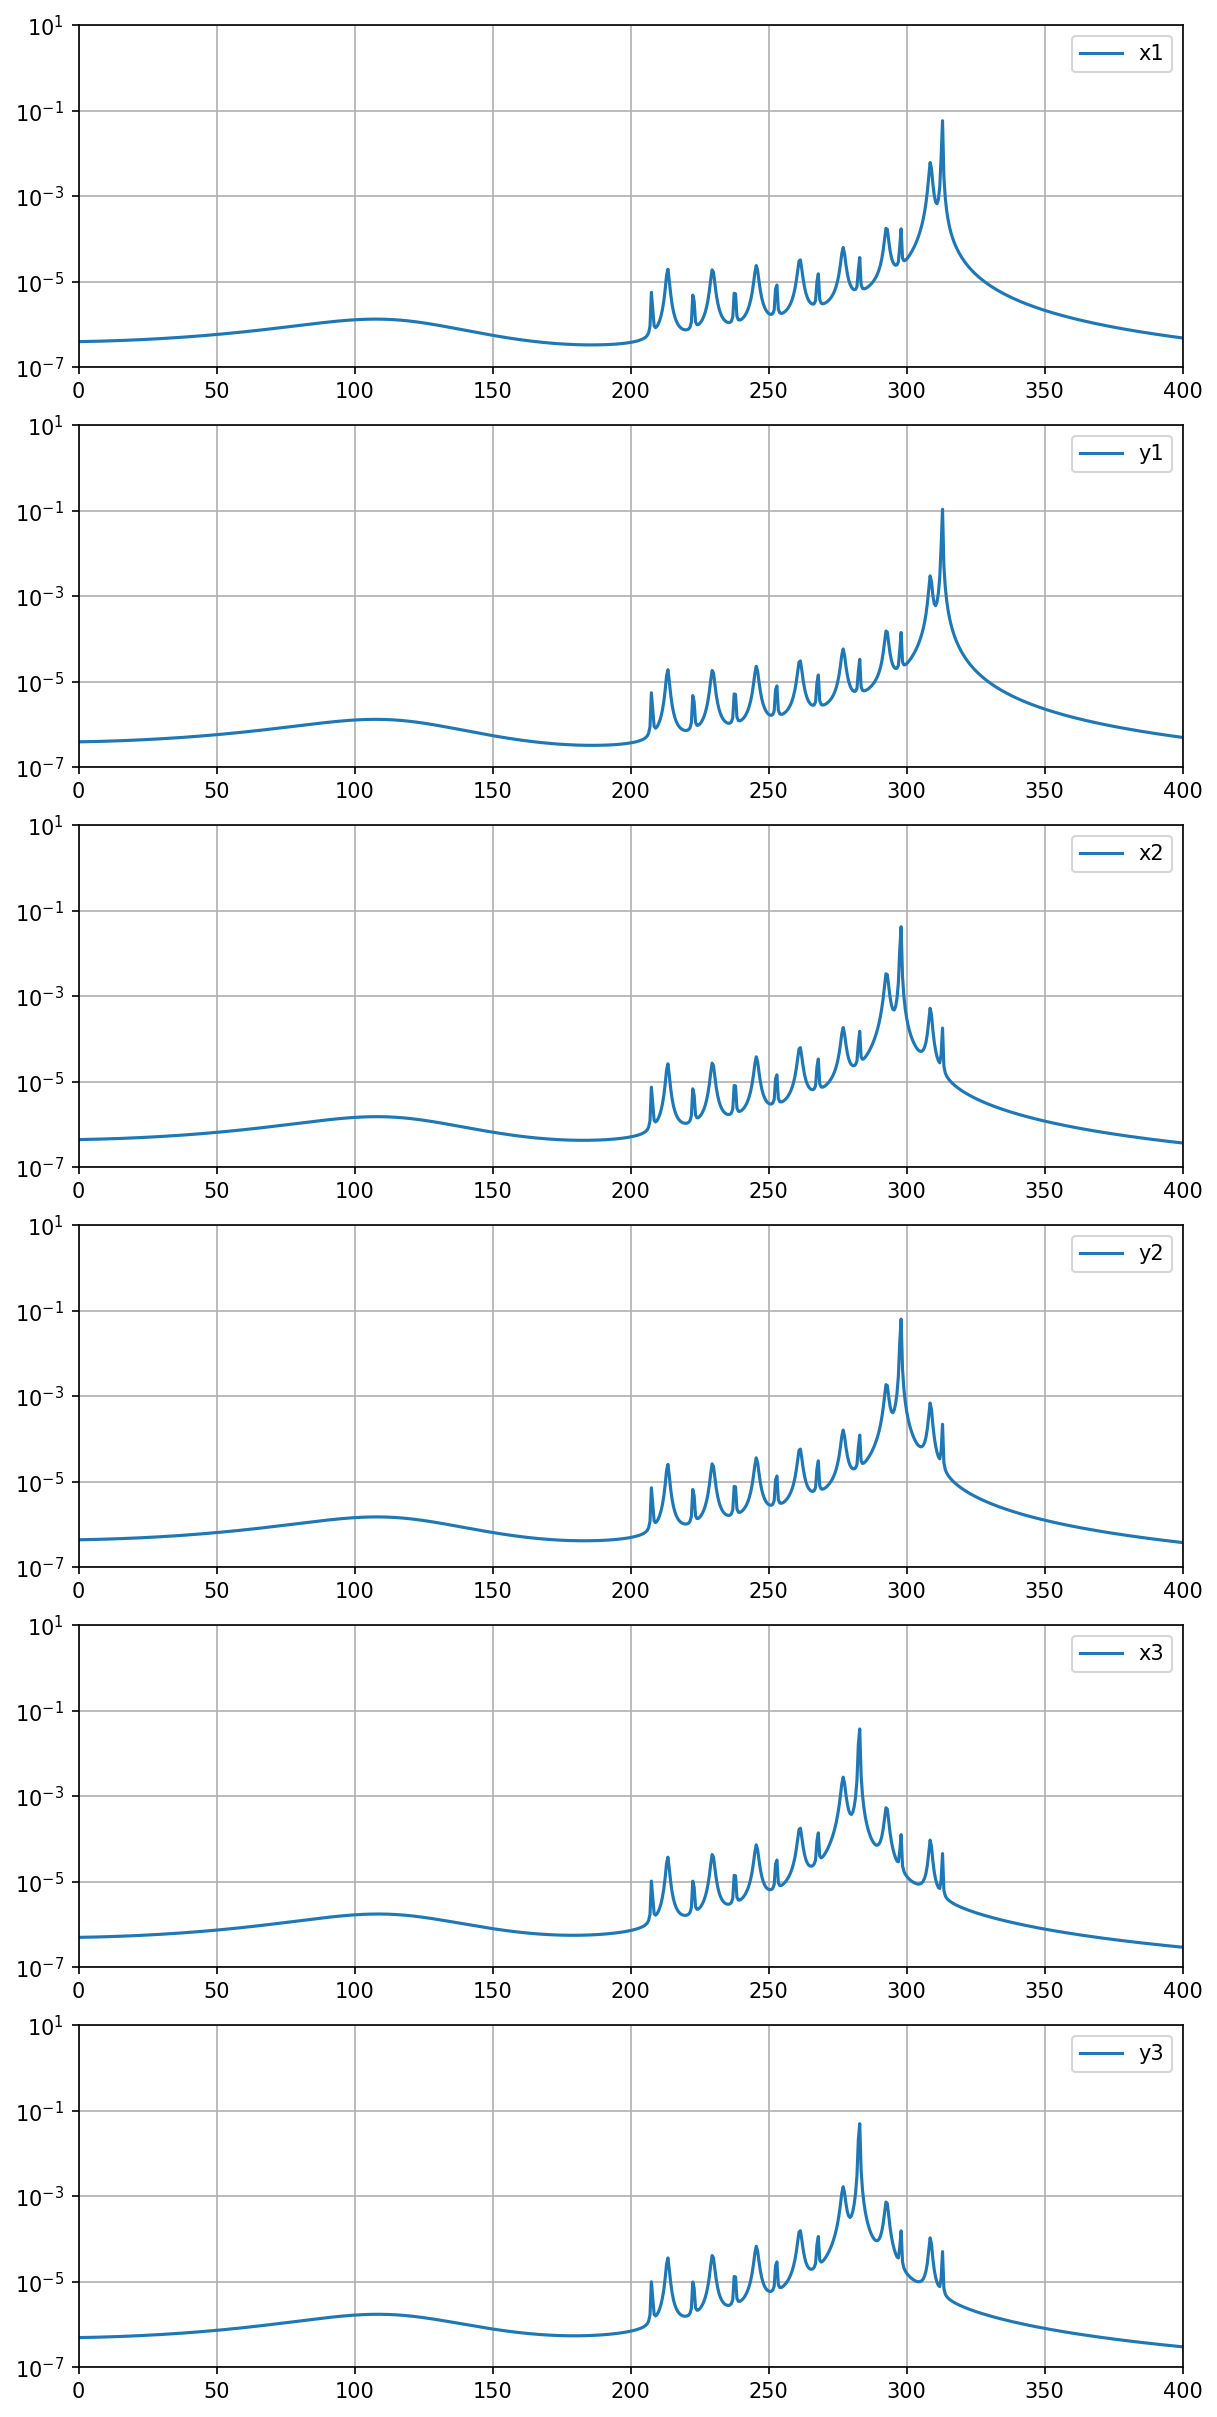

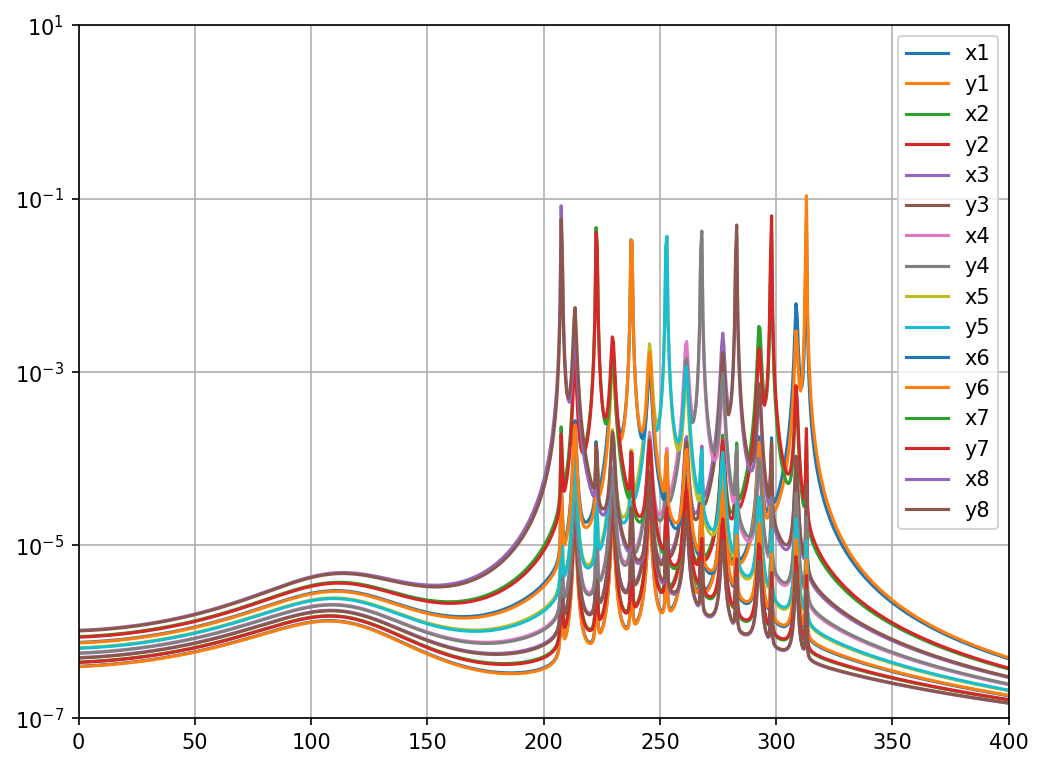

label='x1'
nx1 = 24.304327 phonons
Tx1 via phonons = 3.639242e-04 K
Tx1 via variance = 3.714110e-04 K
label='y1'
ny1 = 37.399996 phonons
Ty1 via phonons = 5.627064e-04 K
Ty1 via variance = 5.702292e-04 K
label='x2'
nx2 = 20.634597 phonons
Tx2 via phonons = 2.941204e-04 K
Tx2 via variance = 3.012473e-04 K
label='y2'
ny2 = 27.014178 phonons
Ty2 via phonons = 3.869981e-04 K
Ty2 via variance = 3.941610e-04 K
label='x3'
nx3 = 20.284032 phonons
Tx3 via phonons = 2.745214e-04 K
Tx3 via variance = 2.812883e-04 K
label='y3'
ny3 = 24.412827 phonons
Ty3 via phonons = 3.321574e-04 K
Ty3 via variance = 3.389603e-04 K
label='x4'
nx4 = 20.881130 phonons
Tx4 via phonons = 2.675704e-04 K
Tx4 via variance = 2.739774e-04 K
label='y4'
ny4 = 23.530682 phonons
Ty4 via phonons = 3.032156e-04 K
Ty4 via variance = 3.096586e-04 K
label='x5'
nx5 = 22.111426 phonons
Tx5 via phonons = 2.674176e-04 K
Tx5 via variance = 2.734647e-04 K
label='y5'
ny5 = 23.430098 phonons
Ty5 via phonons = 2.850525e-04 K
Ty5 via varian

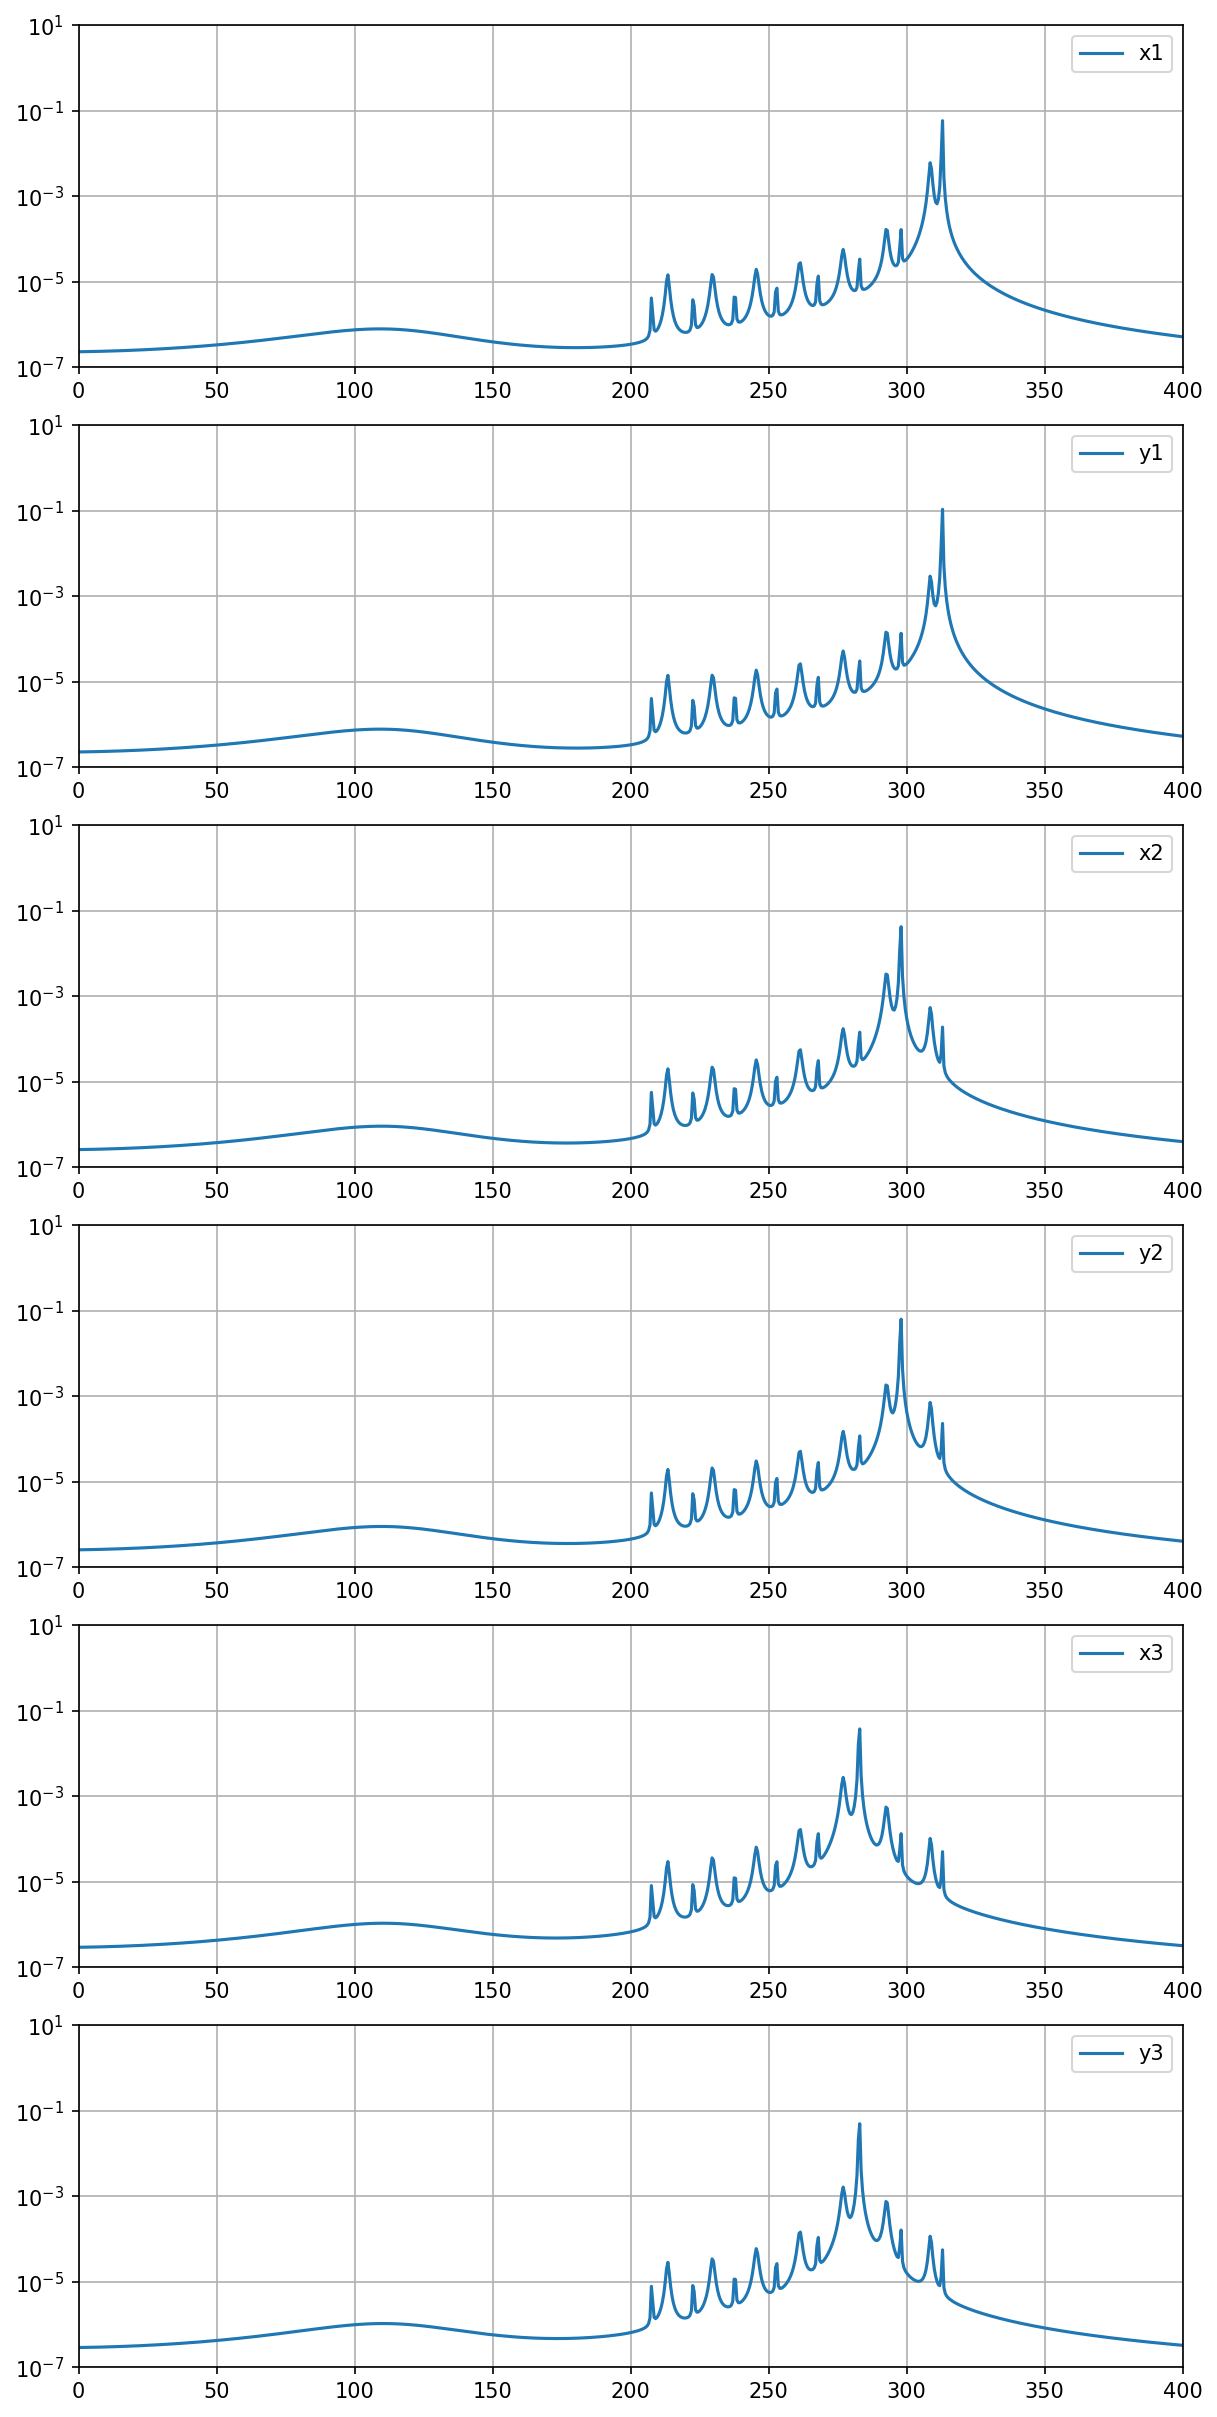

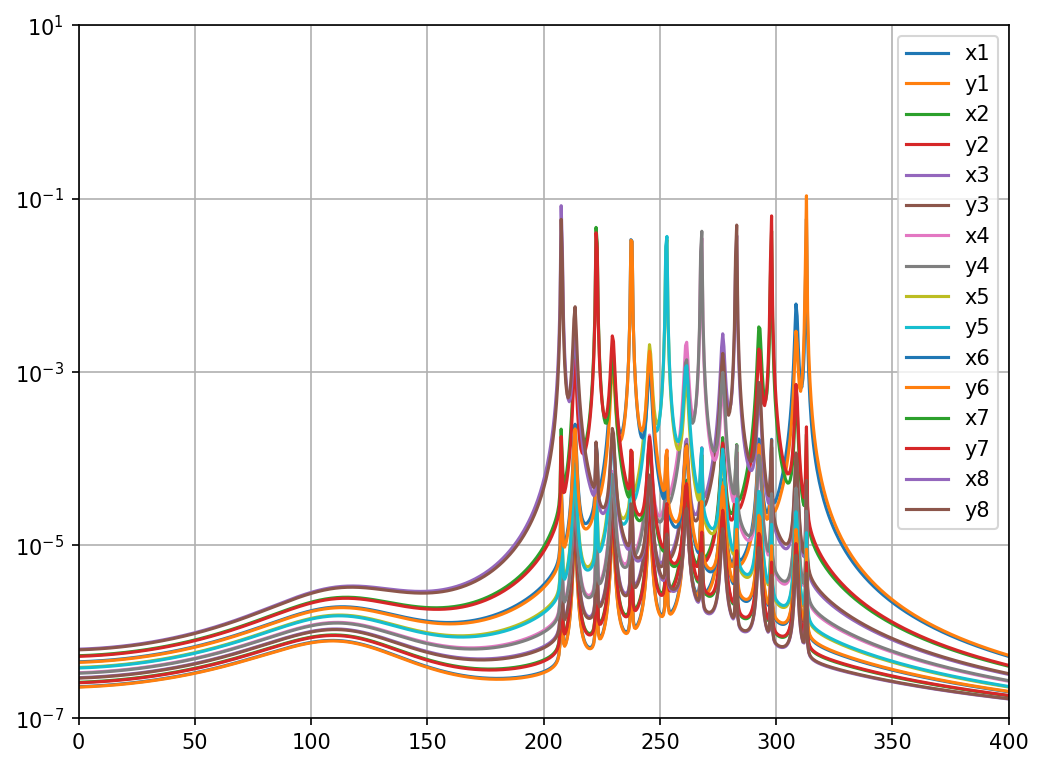

label='x1'
nx1 = 24.224338 phonons
Tx1 via phonons = 3.627265e-04 K
Tx1 via variance = 3.702133e-04 K
label='y1'
ny1 = 37.218816 phonons
Ty1 via phonons = 5.599804e-04 K
Ty1 via variance = 5.675032e-04 K
label='x2'
nx2 = 20.568037 phonons
Tx2 via phonons = 2.931717e-04 K
Tx2 via variance = 3.002986e-04 K
label='y2'
ny2 = 26.868665 phonons
Ty2 via phonons = 3.849135e-04 K
Ty2 via variance = 3.920764e-04 K
label='x3'
nx3 = 20.228026 phonons
Tx3 via phonons = 2.737634e-04 K
Tx3 via variance = 2.805303e-04 K
label='y3'
ny3 = 24.278913 phonons
Ty3 via phonons = 3.303354e-04 K
Ty3 via variance = 3.371383e-04 K
label='x4'
nx4 = 20.837171 phonons
Tx4 via phonons = 2.670071e-04 K
Tx4 via variance = 2.734141e-04 K
label='y4'
ny4 = 23.404828 phonons
Ty4 via phonons = 3.015939e-04 K
Ty4 via variance = 3.080368e-04 K
label='x5'
nx5 = 22.084597 phonons
Tx5 via phonons = 2.670932e-04 K
Tx5 via variance = 2.731402e-04 K
label='y5'
ny5 = 23.314191 phonons
Ty5 via phonons = 2.836423e-04 K
Ty5 via varian

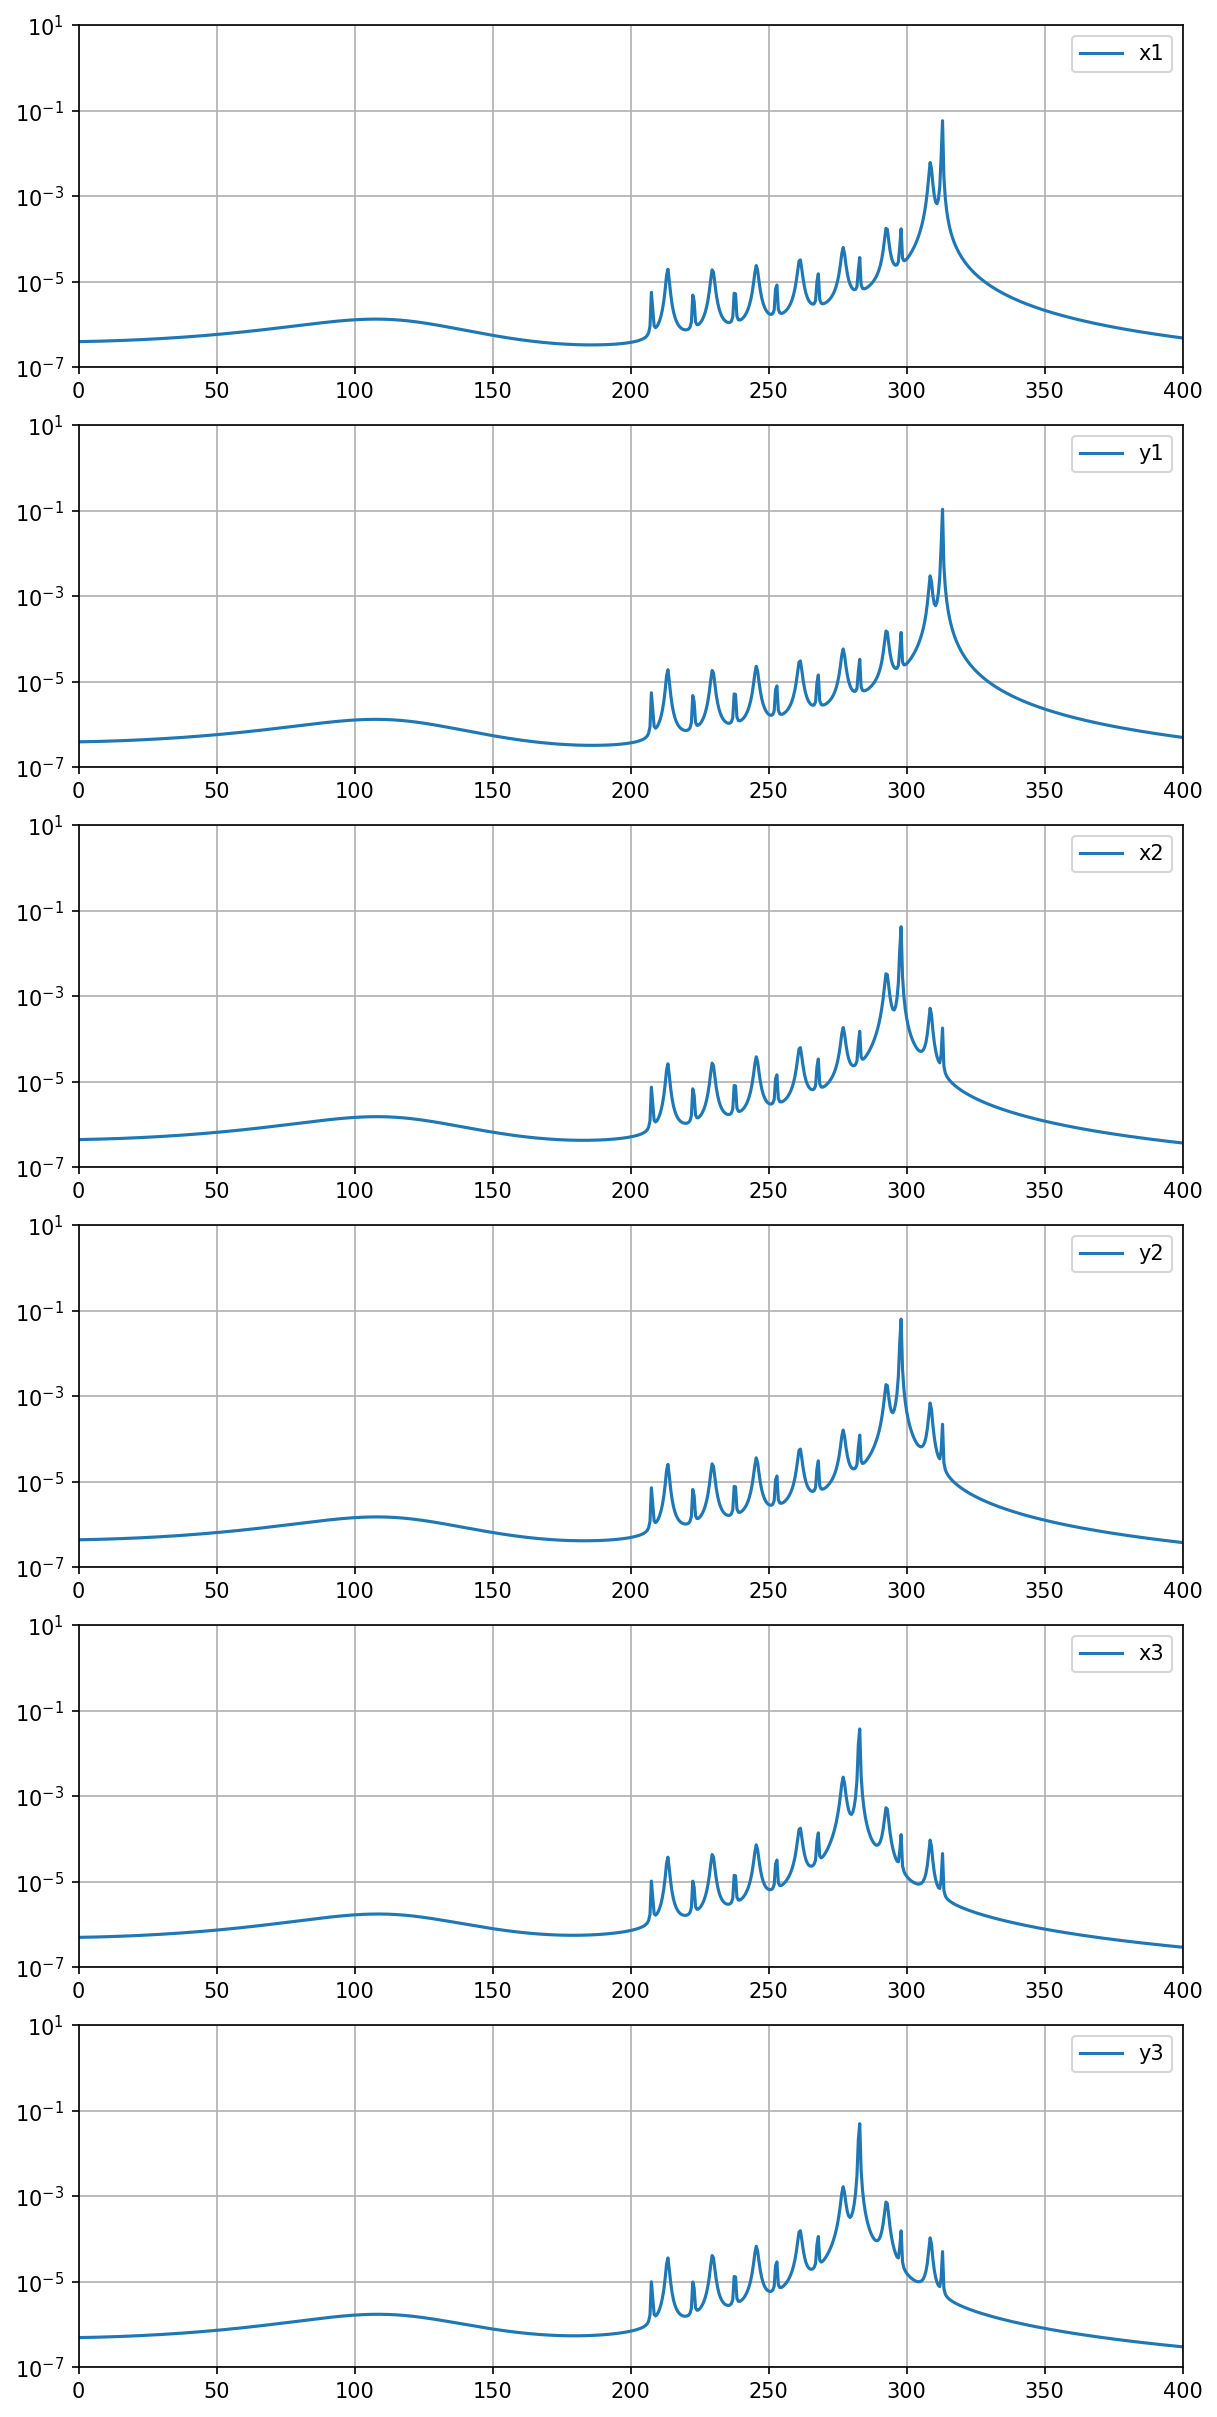

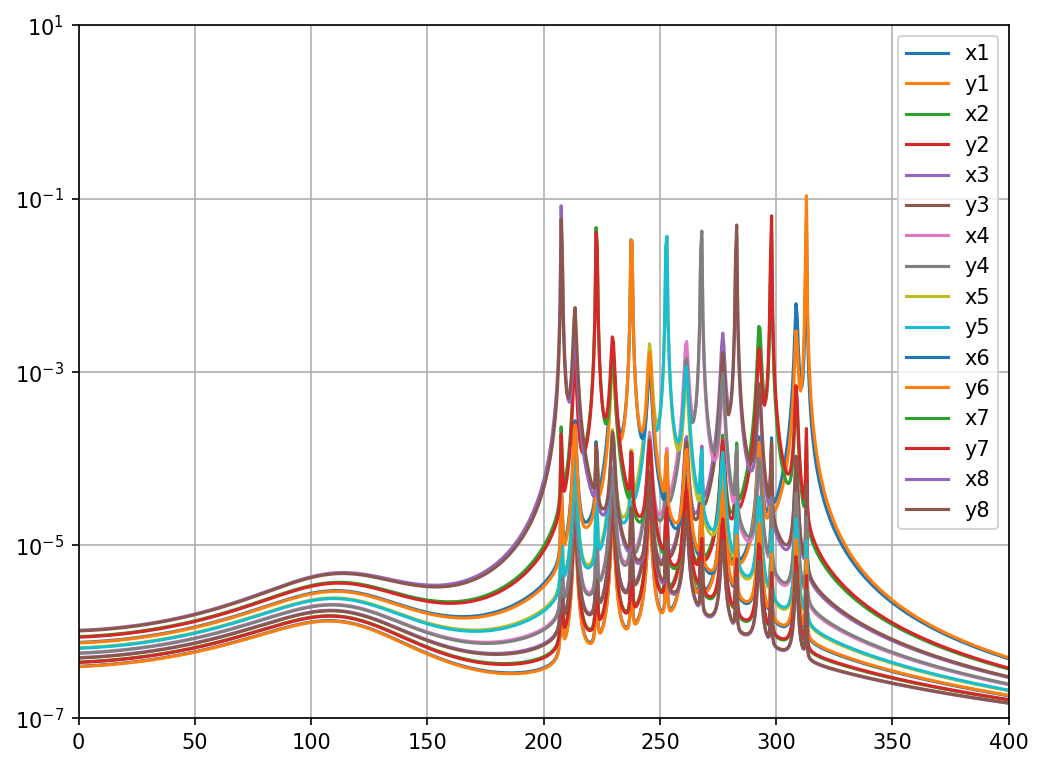

label='x1'
nx1 = 24.304327 phonons
Tx1 via phonons = 3.639242e-04 K
Tx1 via variance = 3.714110e-04 K
label='y1'
ny1 = 37.399996 phonons
Ty1 via phonons = 5.627064e-04 K
Ty1 via variance = 5.702292e-04 K
label='x2'
nx2 = 20.634597 phonons
Tx2 via phonons = 2.941204e-04 K
Tx2 via variance = 3.012473e-04 K
label='y2'
ny2 = 27.014178 phonons
Ty2 via phonons = 3.869981e-04 K
Ty2 via variance = 3.941610e-04 K
label='x3'
nx3 = 20.284032 phonons
Tx3 via phonons = 2.745214e-04 K
Tx3 via variance = 2.812883e-04 K
label='y3'
ny3 = 24.412827 phonons
Ty3 via phonons = 3.321574e-04 K
Ty3 via variance = 3.389603e-04 K
label='x4'
nx4 = 20.881130 phonons
Tx4 via phonons = 2.675704e-04 K
Tx4 via variance = 2.739774e-04 K
label='y4'
ny4 = 23.530682 phonons
Ty4 via phonons = 3.032156e-04 K
Ty4 via variance = 3.096586e-04 K
label='x5'
nx5 = 22.111426 phonons
Tx5 via phonons = 2.674176e-04 K
Tx5 via variance = 2.734647e-04 K
label='y5'
ny5 = 23.430098 phonons
Ty5 via phonons = 2.850525e-04 K
Ty5 via varian

AssertionError: 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️ Failure present! 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️
results_dict={'PSDs': {(LAM, TNT LAM): False, (TNT LAM, Numerical H): False, (LAM, Numerical H): True}}

In [6]:
from levisim.physics.multitrap import *
from levisim.core.units import cm, K
import matplotlib.pyplot as plt
from pprint import pprint as pp
import cv2

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (8, 6)

ω0 = 300*kHz
toy_params = {
    'model': 'pairs',
    'first_Ωx': 312*kHz,
    'Ω_gap': 15*kHz,
    'Ωz_to_Ωx_multiplier': 10,

    'toy_gx': -40*kHz,
    'toy_gy': -40*kHz,

    'use_Γ_formula': True,
}
cavity_kwargs = {
    'Δ': -450*kHz,
    'L': 0.96*cm,
    'Finesse': 40_000,
    'θhom': π/4,
}
gas_kwargs = {
    'P': 1e-6*mbar,
    'T': 300*K,
    'vth': 500,  # m/s
}
N, ax = 8, 2
ω_low, ω_high, ω_step = 0, 400, 0.5
mph = MultiTrap(
    num_traps=N,
    Cartesian_axes_per_trap=ax,
    ω_range=np.arange(ω_low, ω_high, ω_step) * kHz,

    cavity_kwargs=cavity_kwargs,
    gas_kwargs=gas_kwargs,
    toy_params=toy_params,

    setup_hybridisation_power_series=N * ax < 4,
    compare_Rjk_calculations=N * ax < 4,
)

mph.info
mph.cavity.info
mph.gas.info
mph.info_per_dimension

image_dicts = {}
spectral_types = [
    'PSDs',
    'homodyne',
    'heterodyne',
]
QLTM = QuantumLinearTheoryMethod

methods = [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    # QLTM.HYBRID_LINEAR_AMPLIFIER_MODEL,
    QLTM.TNT_LINEAR_AMPLIFIER_MODEL,

    QLTM.NUMERICAL_HYBRIDISATION,
    # QLTM.POWER_SERIES_HYBRIDISATION,
]

if QLTM.TNT_LINEAR_AMPLIFIER_MODEL in methods:
    spectral_types = ['PSDs']

all_plot_values = {}
for spectral_type in spectral_types:
    image_dicts[spectral_type] = {}
    for method in methods:
        all_plot_values[method] = {}
        print(f'{spectral_type} -- {method}')

        label = spectral_type
        if spectral_type == 'PSDs':
            calc_func = mph.calculate_all_hybridised_position_spectra
            label = mph.labels
        elif spectral_type == 'homodyne':
            calc_func = mph.calculate_homodyne_spectrum
        elif spectral_type == 'heterodyne':
            calc_func = mph.calculate_heterodyne_spectrum

        plot_values = calc_func(method)
        all_plot_values[method][spectral_type] = plot_values

        if spectral_type == 'PSDs':
            PSD_fig = plt.figure(layout='constrained', figsize=(8, 16))
            PSD_ax_dict = PSD_fig.subplot_mosaic([
                ['X1'],
                ['Y1'],
                ['X2'],
                ['Y2'],
                ['X3'],
                ['Y3'],
            ])
            PSD_ax_list = list(PSD_ax_dict.values())
            for ii, PSD_ax in enumerate(PSD_ax_list):
                PSD_ax.plot(mph.ω_range / kHz, plot_values[:, ii], label=label[ii])
                PSD_ax.set_yscale('log')
                PSD_ax.legend()
                PSD_ax.grid()
                PSD_ax.set_xlim(ω_low, ω_high)
                PSD_ax.set_ylim(1e-7, 1e1)
            plt.show()

        plt.plot(
            mph.ω_range / kHz,
            plot_values,
            label=label,
        )
        plt.yscale('log')
        plt.legend()
        plt.grid()
        plt.xlim(ω_low, ω_high)
        if spectral_type == 'PSDs':
            plt.ylim(1e-7, 1e1)
        figname = f'{spectral_type} -- {method}.png'
        plt.savefig(figname)
        image_dicts[spectral_type][method] = cv2.imread(figname)
        plt.show()

        if spectral_type == 'PSDs':
            for ii, label in enumerate(mph.labels):
                jn = mph.dimensions[label]
                ħΩ = ħ * jn.Ω

                SQQ_area = np.trapz(plot_values[:, ii], mph.ω_range / Hz)
                njn = 0.5 * (SQQ_area - 1)
                print(f'{label=}')
                print(f'n{label} = {njn:.6f} phonons')
                print(f'T{label} via phonons = {njn * ħΩ / kB:.6e} K')

                eqp_f = jn.m * jn.Ω**2 / kB
                q_variance = SQQ_area * jn.zpf**2
                print(f'T{label} via variance = {eqp_f * q_variance:.6e} K')


method_pairs = []
# comparing 2
if len(methods) >= 2:
    method_pairs.append((methods[0], methods[1]))

# comparing 3
if len(methods) >= 3:
    method_pairs.append((methods[1], methods[2]))
    method_pairs.append((methods[0], methods[2]))

# comparing 4
if len(methods) >= 4:
    method_pairs.append((methods[2], methods[3]))
    method_pairs.append((methods[0], methods[3]))
    method_pairs.append((methods[1], methods[3]))

# comparing 5
if len(methods) >= 5:
    method_pairs.append((methods[3], methods[4]))
    method_pairs.append((methods[0], methods[4]))
    method_pairs.append((methods[1], methods[4]))
    method_pairs.append((methods[2], methods[4]))


def greyscale_diff(image_1, image_2):
    return cv2.cvtColor(cv2.subtract(image_1, image_2), cv2.COLOR_BGR2GRAY)

results_dict = {}
all_results = []
for spectral_type, image_dict in image_dicts.items():

    results_dict[spectral_type] = {}

    for method_pair in method_pairs:
        diff = greyscale_diff(image_dict[method_pair[0]], image_dict[method_pair[1]])
        result = cv2.countNonZero(diff) == 0

        all_results.append(result)
        results_dict[spectral_type][method_pair] = result

assert all(all_results), f'🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️ Failure present! 🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️🏴‍☠️\n{results_dict=}'
print('🎉🎉🎉🎉🎉 all spectral calculation methods agree :) 🎉🎉🎉🎉🎉')
pp(results_dict)


# Compare Tania's Fortran to my code

In [7]:
mph.ω_range[:20] / kHz

array([0. , 0.5, 1. , 1.5, 2. , 2.5, 3. , 3.5, 4. , 4.5, 5. , 5.5, 6. ,
       6.5, 7. , 7.5, 8. , 8.5, 9. , 9.5])

In [8]:
xyz_data[:, 0][:20]

array([ 0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ,  5.5,
        6. ,  6.5,  7. ,  7.5,  8. ,  8.5,  9. ,  9.5, 10. ])

In [9]:
xyz_data[:, 1][:20]

array([4.006651e-07, 4.012007e-07, 4.017570e-07, 4.023340e-07,
       4.029319e-07, 4.035508e-07, 4.041907e-07, 4.048517e-07,
       4.055342e-07, 4.062379e-07, 4.069632e-07, 4.077104e-07,
       4.084791e-07, 4.092699e-07, 4.100826e-07, 4.109177e-07,
       4.117750e-07, 4.126549e-07, 4.135576e-07, 4.144830e-07])

In [10]:
method = QLTM.LINEAR_AMPLIFIER_MODEL
all_plot_values[method]['PSDs'][:, 0][1:21]

array([4.00665084e-07, 4.01200675e-07, 4.01756939e-07, 4.02333967e-07,
       4.02931856e-07, 4.03550708e-07, 4.04190628e-07, 4.04851727e-07,
       4.05534118e-07, 4.06237920e-07, 4.06963258e-07, 4.07710258e-07,
       4.08479054e-07, 4.09269782e-07, 4.10082585e-07, 4.10917608e-07,
       4.11775005e-07, 4.12654929e-07, 4.13557544e-07, 4.14483014e-07])

In [11]:
rtol = 1e-5
method = QLTM.LINEAR_AMPLIFIER_MODEL
for ii in range(len(opt_data[:, 1])):
    if not QLTM.TNT_LINEAR_AMPLIFIER_MODEL in all_plot_values.keys():
        assert np.isclose(opt_data[:, 1][ii], all_plot_values[method]['heterodyne'][ii], rtol=rtol)
        assert np.isclose(opt_data[:, 2][ii], all_plot_values[method]['homodyne'][ii], rtol=rtol)
    for jj in range(1, xyz_data.shape[1]):
        # the first column of xyz_data are the frequencies, hence jj and jj - 1
        # the first entries are off shifted off by one, hence ii and ii + 1
        assert np.isclose(xyz_data[:, jj][ii], all_plot_values[method]['PSDs'][:, jj - 1][ii + 1], rtol=rtol)


# Difference in constant values

In [12]:
(kB / 1.4e-23 - 1) * 100

-1.3822142857142672

In [13]:
(ħ / 1.05e-34 - 1) * 100

0.43541120439585246

# DEBUG output at arbitrary frequency value $\omega = 298$ kHz (to compare to Fortran)

In [15]:
from levisim import *

print('quanta_per_operator', mph.quantum_factor_per_noise_operator)
print('phases', [dim.φ for dim in mph.dimensions.values()])
print('kappa (kHz)', mph.cavity.κ / kHz)

omega = 298*kHz

print('light_couplings_array')
print(mph.G_array / kHz)

chi_C = mph.cavity.χC(omega)
print(f'{chi_C=}')
chi_C_star = np.conjugate(mph.cavity.χC(-omega))
print(f'{chi_C=}')
eta_0 = mph.cavity.ηm(298*kHz)
print(f'{eta_0=}')

for label, dim in mph.dimensions.items():
    print(f'eta_M {label}', dim.μm(omega))

print('M_norm_array')
ii = 0
for label, dim in mph.dimensions.items():
    print(1 + mph.G_array[ii]**2 * dim.μm(omega) * eta_0)
    ii += 1

print('Beta_M')
ii = 0
for label, dim in mph.dimensions.items():
    print(1j * np.sqrt(mph.cavity.κ) * dim.μm(omega) * mph.G_array[ii])
    ii += 1

print('X1D_noise_vector')
ii = 0
for label, dim in mph.dimensions.items():
    # print(mph.X1D(298*kHz))
    if ii < 4:
        print(label, '1D', dim.Q1D(omega))
    ii += 1


for method in [
    QLTM.LINEAR_AMPLIFIER_MODEL,
    QLTM.NUMERICAL_HYBRIDISATION,
]:
    print(method)
    a_out_hat, a_out_dag = mph.output_light_noise_vectors(method, omega)
    X_noise_vector = mph.hybridised_X(method, omega)
    print(f'{a_out_hat=}')
    print(f'{a_out_dag=}')
    print(f'{X_noise_vector=}')
    mph.calculate_all_hybridised_position_spectra

print('Rjks')
Rx1y1 = HybridisationTerm(1, [('x1', 'y1')])
Rx1x2 = HybridisationTerm(1, [('x1', 'x2')])
Ry1y2 = HybridisationTerm(1, [('y1', 'y2')])
print(mph.hybridisation_term_value(Rx1y1, omega))
print(mph.hybridisation_term_value(Rx1x2, omega))
print(mph.hybridisation_term_value(Ry1y2, omega))


quanta_per_operator [1, 0, 20035211.151405744, 20035210.151405744, 19939348.945593044, 19939347.945593044, 21047090.555072013, 21047089.555072013, 20941326.23627984, 20941325.23627984, 22166616.606255982, 22166615.606255982, 22049332.870675124, 22049331.870675124, 23411932.102701038, 23411931.102701038, 23281139.129985157, 23281138.129985157, 24805499.445594102, 24805498.445594102, 24658721.41418296, 24658720.41418296, 26375467.720033493, 26375466.720033493, 26209584.355877846, 26209583.355877846, 28157593.87205005, 28157592.87205005, 27968616.823179856, 27968615.823179856, 30197999.179996457, 30197998.179996457, 29980747.4914282, 29980746.4914282]
phases [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
kappa (kHz) 390.3547630208334
light_couplings_array
[-40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j
 -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j -40.+0.j]
chi_C=(5.075874754925432e-07-3.952983469590655e-07j)
chi

In [16]:
for dim in mph.dimensions.values():
    print(dim, dim.Ω / kHz, 1.4e-23 * 300 / (1.05e-34 * dim.Ω), kB * 300.0 / (ħ * dim.Ω))

Dimension(x1) 312.0 20404479.883576326 20035210.69550728
Dimension(y1) 313.5 20306850.793224283 19939348.44337567
Dimension(x2) 297.0 21435009.170625634 21047090.023563206
Dimension(y2) 298.5 21327295.556702893 20941325.752088014
Dimension(x3) 282.0 22575169.232892957 22166616.088646352
Dimension(y3) 283.5 22455723.893036377 22049332.405637644
Dimension(x4) 267.0 23843437.16732514 23411931.599244464
Dimension(y4) 268.5 23710233.607731145 23281138.685282204
Dimension(x5) 252.0 25262689.379665922 24805498.95634235
Dimension(y5) 253.5 25113206.010555476 24658720.85600896
Dimension(x6) 237.0 26861593.77078402 26375467.244718447
Dimension(y6) 238.49999999999997 26692652.92945834 26209583.802927766
Dimension(x7) 222.0 28676566.322864022 28157593.409902126
Dimension(y7) 223.5 28484106.146200508 27968616.27292292
Dimension(x8) 207.00000000000003 30754578.37524547 30197998.72946025
Dimension(y8) 208.50000000000003 30533322.415711332 29980746.940039672


In [17]:
for dim in mph.dimensions.values():
    print(dim, dim.noise_phonons_exact, dim.noise_phonons_approx)

Dimension(x1) 20035210.151405744 20035210.69550728
Dimension(y1) 19939347.945593044 19939348.44337567
Dimension(x2) 21047089.555072013 21047090.023563206
Dimension(y2) 20941325.23627984 20941325.752088014
Dimension(x3) 22166615.606255982 22166616.088646352
Dimension(y3) 22049331.870675124 22049332.405637644
Dimension(x4) 23411931.102701038 23411931.599244464
Dimension(y4) 23281138.129985157 23281138.685282204
Dimension(x5) 24805498.445594102 24805498.95634235
Dimension(y5) 24658720.41418296 24658720.85600896
Dimension(x6) 26375466.720033493 26375467.244718447
Dimension(y6) 26209583.355877846 26209583.802927766
Dimension(x7) 28157592.87205005 28157593.409902126
Dimension(y7) 27968615.823179856 27968616.27292292
Dimension(x8) 30197998.179996457 30197998.72946025
Dimension(y8) 29980746.4914282 29980746.940039672


# sin(π) = 0 only in sympy, not numpy

In [18]:
sympy.sin(sympy.pi)

0

In [19]:
np.sin(π)

1.2246467991473532e-16

# Investigating $S_{cc^\dagger}(\omega)$

/opt/homebrew/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1335: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


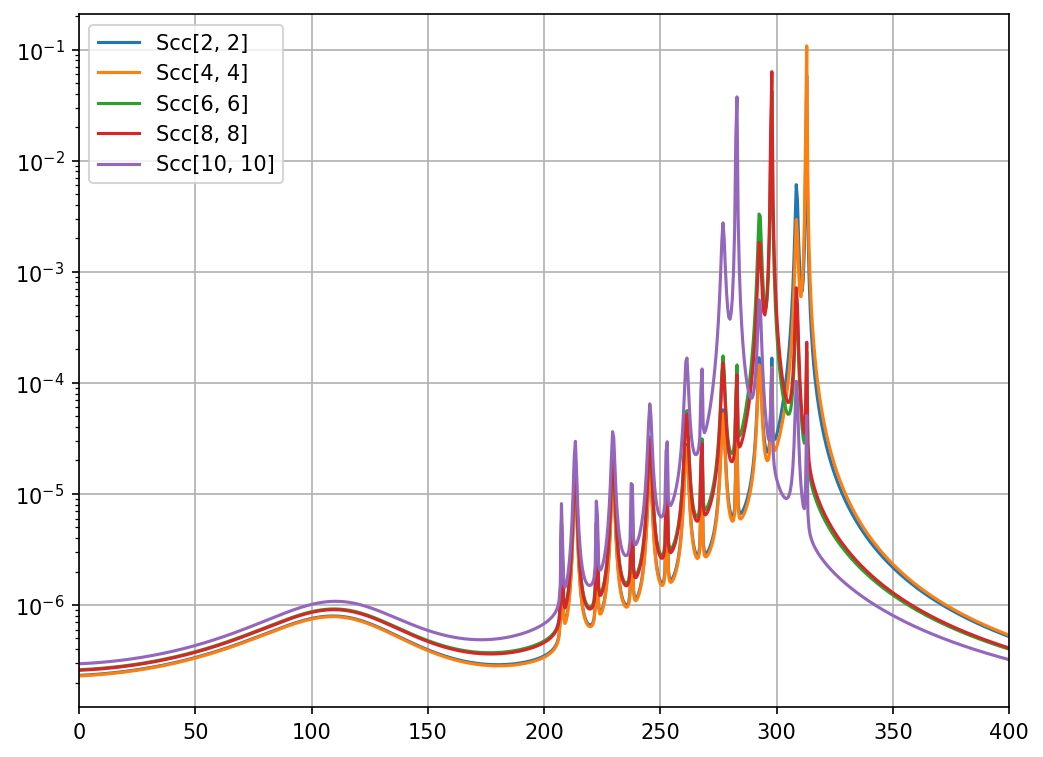

In [20]:
Scc = mph.quantum_operator_spectral_density_array
row, col = 2, 2
for row in np.arange(2, 12, 2):
    col = row
    # col = row + 1
    # row = col
    plt.plot(
        mph.ω_range / kHz,
        Scc[:, row, col] + Scc[:, row + 1, col + 1],
        label=f'Scc[{row}, {col}]',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()


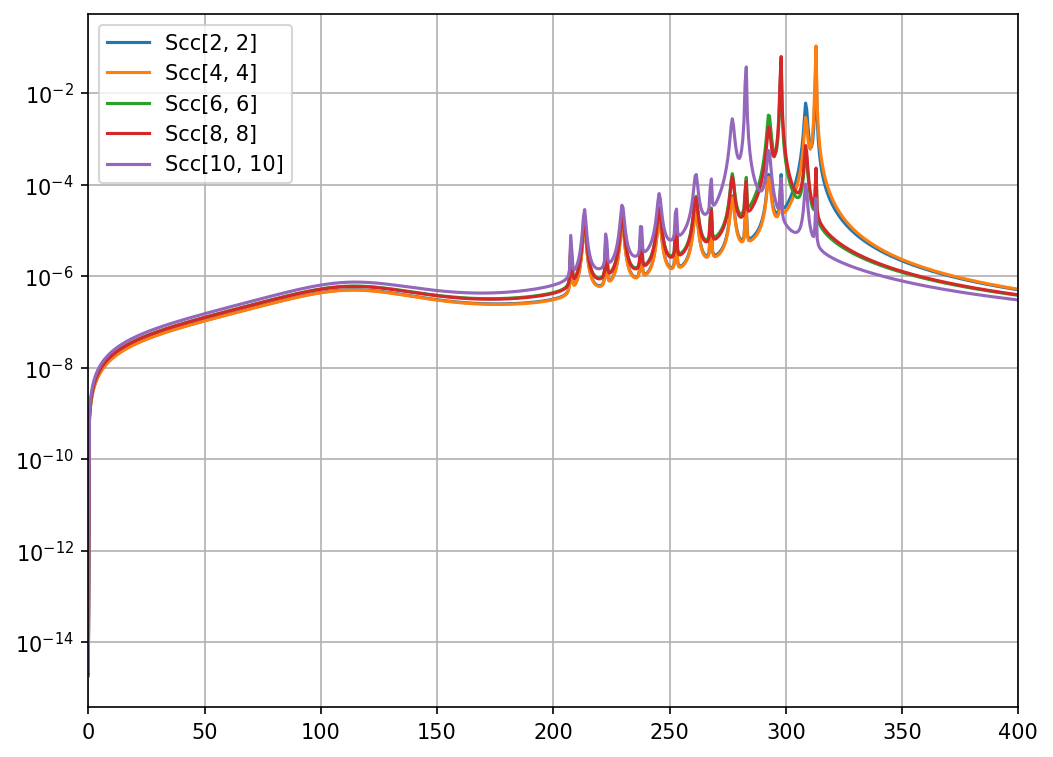

In [21]:
# NOTE: momentum spectra???
Scc = mph.quantum_operator_spectral_density_array
row, col = 2, 2
for row in np.arange(2, 12, 2):
    col = row
    # col = row + 1
    # row = col
    plt.plot(
        mph.ω_range / kHz,
        # 1j * (Scc[:, row, col] - Scc[:, row + 1, col + 1]),
        np.abs(1j * (Scc[:, row + 1, col + 1] - Scc[:, row, col])),
        label=f'Scc[{row}, {col}]',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()

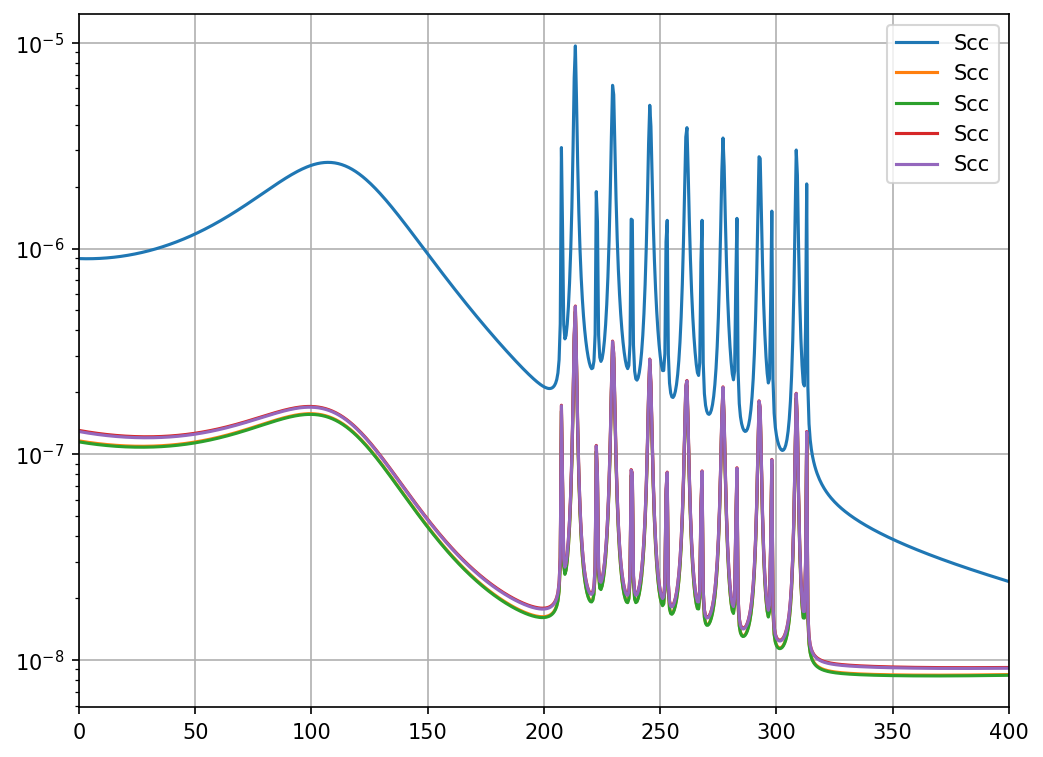

In [22]:
for ii in range(5):
    plt.plot(
        mph.ω_range / kHz,
        Scc[:, 2*ii + 1, 2*ii + 1],
        label='Scc',
    )
plt.yscale('log')
plt.legend()
plt.grid()
plt.xlim(ω_low, ω_high)
plt.show()